# Early mistakes and later MATHStream assessment errors

**Dasey Dang · Carnegie Learning capstone · Main analysis**

**Research question.** Are early mistakes linked to more errors on later MATHStream assessments?

The unit is one student–attempt. I count mistakes among the first three distinct, recorded in-stream activities and compare the average share of later scored assessment responses that were incorrect. Each attempt contributes one rate and gets equal weight. The completion analysis is available in `03_early_errors_completion.ipynb`.

Run top to bottom from a fresh Python kernel. See `MATHStream_Reproducibility.md` for setup and the codebook. The notebook writes aggregate results to `results/assessment_errors/`.

## 1. Load and validate the exports

The question export supplies response order, item type and correctness. The attempt export supplies status, pass and score fields for the audit and stream/class metadata for subgroup analyses. The join key is `anon_userid` plus `attemptid`. Timestamps with no offset are treated as UTC for ordering, as in the assessment draft. Confirm timestamp conventions if the extract changes.

In [1]:
import os
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

# Set MATHSTREAM_DATA_DIR to use a private input directory outside the repository.
cwd = Path.cwd()
root = cwd.parent if cwd.name in {"notebooks", "02_notebook"} else cwd
data_dir = Path(os.environ.get("MATHSTREAM_DATA_DIR", root / "data" / "raw")).expanduser()
results = root / "results" / "assessment_errors"
keys = ["anon_userid", "attemptid"]
scored_states = ["CORRECT", "INCORRECT"]

# Token rules from the working analysis. Review the mapping audit for a new extract.
stream_token = r"(?:^|_)VS(?:_|$)"
assessment_tokens = r"(?:^|_)(?:CP|SP)(?:_|$)"
min_stream_attempts = 30
max_streams = 6
min_class_attempts = 10

In [2]:
attempt_fields = ["status", "passedattempt", "score", "scoremaximum", "lessonstreamname", "anon_classid"]

def read_export(filename, required):
    path = data_dir / filename
    if not path.is_file():
        raise FileNotFoundError(f"Expected {path}. See MATHStream_Reproducibility.md.")
    fields = set(required)
    frame = pd.read_csv(
        path, dtype="string", usecols=lambda name: name.lower() in fields
    )
    frame.columns = frame.columns.str.lower()
    missing = fields.difference(frame.columns)
    if missing:
        raise ValueError(f"{filename} is missing required columns: {sorted(missing)}")
    return frame


q = read_export("question-data-anonymized.csv",
                keys + ["activityid", "responsedate", "activityresponsestate"])
a = read_export("attempt-data-anonymized.csv", keys + attempt_fields)
for name, frame, identifiers in [
    ("Question", q, keys + ["activityid"]), ("Attempt", a, keys)
]:
    if frame[identifiers].isna().any().any():
        raise ValueError(f"{name} file contains missing identifiers.")
if a.duplicated(keys).any():
    raise ValueError("Attempt file has duplicate student–attempt keys.")

q["responsedate"] = pd.to_datetime(
    q["responsedate"], format="mixed", errors="raise", utc=True
)
if q["responsedate"].isna().any():
    raise ValueError("Question file has missing response timestamps.")
q["state"] = q["activityresponsestate"].str.strip().str.upper()
q["scored"] = q["state"].isin(scored_states)
q["wrong"] = q["state"].eq("INCORRECT").fillna(False)
a["status"] = a["status"].str.strip().str.upper()

# Source row order breaks ties when repeated responses to the same item share a timestamp.
q["source_row"] = np.arange(len(q))
items = (
    q.sort_values(keys + ["responsedate", "source_row"])
    .drop_duplicates(keys + ["activityid"], keep="first")
    .copy()
)
audit = pd.Series({
    "Question export rows": len(q),
    "Attempt export rows": len(a),
    "Distinct student–attempt–activity rows": len(items),
    "Repeated activity rows removed": len(q) - len(items),
}, name="count")
display(audit.to_frame())
display(q["state"].value_counts(dropna=False).rename("question_rows").to_frame())
results.mkdir(parents=True, exist_ok=True)

,count
Question export rows,1207408
Attempt export rows,196587
Distinct student–attempt–activity rows,1207369
Repeated activity rows removed,39


,question_rows
state,
INCORRECT,670545
CORRECT,529002
SKIPPED_WITH_ANSWER_PASS,7861


## 2. Classify item IDs

Use underscore-delimited tokens anywhere in the item ID. `VS` alone identifies an in-stream item. `CP` or `SP` without `VS` identifies an assessment item. IDs with both kinds of token or neither are omitted from the predictor and outcome. Review coverage and examples against Carnegie's item convention for each new extract.

In [3]:
activity_id = items["activityid"]
has_stream_token = activity_id.str.contains(stream_token, case=False, regex=True, na=False).to_numpy(dtype=bool)
has_assessment_token = activity_id.str.contains(assessment_tokens, case=False, regex=True, na=False).to_numpy(dtype=bool)
items["item_type"] = np.select(
    [has_stream_token & ~has_assessment_token, has_assessment_token & ~has_stream_token,
     has_stream_token & has_assessment_token],
    ["In-stream", "Assessment", "Both tokens"],
    default="Neither token",
)
mapping = items.groupby("item_type").agg(
    activity_records=("activityid", "size"),
    unique_item_ids=("activityid", "nunique"),
)
display(mapping)
for label, group in items.groupby("item_type"):
    print(f"{label}: {', '.join(group['activityid'].drop_duplicates().head(3))}")
mapping.to_csv(results / "item_mapping_audit.csv")
if not {"In-stream", "Assessment"}.issubset(mapping.index):
    raise ValueError("Both mapped item types must appear. Review the activity ID token rules.")

,activity_records,unique_item_ids
item_type,,
Assessment,416909,3588
Both tokens,6298,34
In-stream,772787,4064
Neither token,11375,62


Assessment: AR-VST-0091-8.EE.8b-3_SP_004, AR-VST-0091-8.EE.8b-3_SP_006, AR-VST-0091-8.EE.8b-3_SP_007
Both tokens: HSMB_A1_M03_T01_L02_S01_VS_CP_001, HSMB_A1_M04_T01_L03_S01_VS_CP_001, HSMB_A1_M04_T02_L01_S01_VS_CP_001
In-stream: AR-VST-0019-6.SP.4-2_VS_S1_001, AR-VST-0019-6.SP.4-2_VS_S2_001, AR-VST-0019-6.SP.4-2_VS_AS2_001
Neither token: MSMB_C03_M01_T02_L02_S02_A03_S1_001, MSMB_C03_M01_T02_L02_S02_A03_S2_001, MSMB_C03_M01_T02_L02_S02_A03_S3_001


## 3. Define early errors and assessment eligibility

Keep attempts with three in-stream activities whose first recorded responses were all scored. Exclude ties between distinct in-stream activities when a tie involves any of the first three. Require the earliest mapped assessment record, including a skip, to occur strictly after the third in-stream response. Keep attempts with at least one scored assessment item. The outcome denominator counts scored assessment items only.

The coverage table starts with all attempts with a usable early window. It shows how many also have an eligible assessment outcome at each early-error level.

In [4]:
in_stream = items.loc[items["item_type"].eq("In-stream")].copy()
in_stream["time_tie"] = in_stream.duplicated(keys + ["responsedate"], keep=False)
first_three = in_stream.groupby(keys, sort=False).head(3)
early_windows = first_three.groupby(keys, sort=False).agg(
    early_n=("activityid", "size"),
    valid_n=("scored", "sum"),
    early_errors=("wrong", "sum"),
    third_time=("responsedate", "max"),
    time_tie=("time_tie", "any"),
).reset_index()
reached_three = early_windows.loc[early_windows["early_n"].eq(3)]
scored_three = reached_three.loc[reached_three["valid_n"].eq(3)]
early = scored_three.loc[~scored_three["time_tie"]].copy()

assessment_items = items.loc[items["item_type"].eq("Assessment")]
later = assessment_items.groupby(keys, sort=False).agg(
    assessment_start=("responsedate", "min"),
    assessed_items=("scored", "sum"),
    assessment_errors=("wrong", "sum"),
).reset_index()
cohort = early.merge(later, on=keys, how="left", validate="one_to_one")
has_assessment = cohort["assessment_start"].notna()
ordered_assessment = cohort["assessment_start"].gt(cohort["third_time"])
cohort["eligible_assessment"] = ordered_assessment & cohort["assessed_items"].gt(0)
eligible = cohort.loc[cohort["eligible_assessment"]].copy()
if eligible.empty:
    raise ValueError("No attempts met the early-window and later scored assessment rules.")
eligible["error_rate"] = eligible["assessment_errors"] / eligible["assessed_items"]

meta = a[keys + ["lessonstreamname", "anon_classid"]]
assessment = eligible.merge(meta, on=keys, how="left", validate="one_to_one", indicator=True)

cohort_audit = pd.Series({
    "Attempts with any mapped in-stream activity": len(early_windows),
    "At least three distinct in-stream activities": len(reached_three),
    "All first three in-stream responses scored": len(scored_three),
    "Clear order for first three in-stream activities": len(early),
    "Any mapped assessment observed": has_assessment.sum(),
    "Earliest assessment strictly after third in-stream response": ordered_assessment.sum(),
    "Later assessment includes a scored item": len(eligible),
    "Eligible attempts linked to attempt metadata": assessment["_merge"].eq("both").sum(),
    "Eligible attempts with missing stream name": assessment["lessonstreamname"].isna().sum(),
    "Eligible attempts with missing class ID": assessment["anon_classid"].isna().sum(),
}, name="count")
display(cohort_audit.to_frame())
cohort_audit.to_csv(results / "cohort_audit.csv", header=True)

coverage = cohort.groupby("early_errors").agg(
    early_attempts=("attemptid", "size"),
    eligible_assessment_attempts=("eligible_assessment", "sum"),
).reindex(range(4), fill_value=0)
coverage["eligible_assessment_pct"] = (
    100 * coverage["eligible_assessment_attempts"] / coverage["early_attempts"].replace(0, np.nan)
)
display(coverage.round(2))
coverage.to_csv(results / "assessment_coverage_by_early_errors.csv")

,count
Attempts with any mapped in-stream activity,172766
At least three distinct in-stream activities,145771
All first three in-stream responses scored,142466
Clear order for first three in-stream activities,142466
Any mapped assessment observed,118721
Earliest assessment strictly after third in-stream response,118721
Later assessment includes a scored item,118603
Eligible attempts linked to attempt metadata,118588
Eligible attempts with missing stream name,15
Eligible attempts with missing class ID,15


,early_attempts,eligible_assessment_attempts,eligible_assessment_pct
early_errors,,,
0,22539,20607,91.43
1,38534,33510,86.96
2,42618,34670,81.35
3,38775,29816,76.89


## 4. Compare assessment error rates across early-error groups

The main comparison uses the question records for eligibility. Attempts missing metadata still contribute to the pooled comparison. Stream and class analyses require their respective metadata. The pooled difference is descriptive. Students can contribute several attempts, and differences in prior skill, class or item difficulty could contribute to the pattern.

,attempts,students,assessment_items,mean_error_pct
early_errors,,,,
0,20607,8327,72170,28.35
1,33510,12771,110425,42.18
2,34670,13753,106008,60.44
3,29816,10998,84927,79.37


Three versus zero early mistakes: +51.0 percentage points.


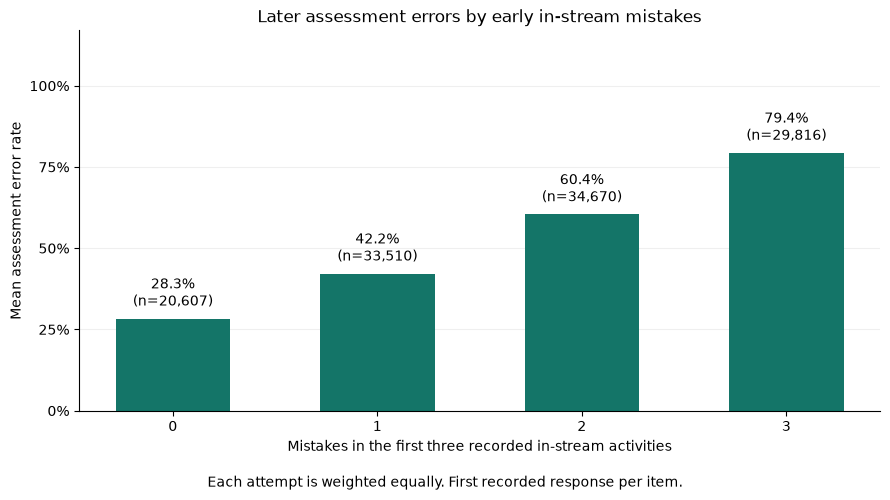

In [5]:
out = eligible.groupby("early_errors").agg(
    attempts=("attemptid", "size"),
    students=("anon_userid", "nunique"),
    assessment_items=("assessed_items", "sum"),
    mean_error_rate=("error_rate", "mean"),
).reindex(range(4))
count_cols = ["attempts", "students", "assessment_items"]
out[count_cols] = out[count_cols].fillna(0).astype(int)
out["mean_error_pct"] = 100 * out["mean_error_rate"]
display(out[["attempts", "students", "assessment_items", "mean_error_pct"]].round(2))
out.to_csv(results / "assessment_errors_by_early_mistakes.csv")
if out.loc[[0, 3], "mean_error_pct"].notna().all():
    gap = out.loc[3, "mean_error_pct"] - out.loc[0, "mean_error_pct"]
    print(f"Three versus zero early mistakes: {gap:+.1f} percentage points.")

plot = out.dropna(subset=["mean_error_pct"])
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(plot.index, plot["mean_error_pct"], color="#147568", width=.56)
labels = [f"{pct:.1f}%\n(n={n:,})" for pct, n in zip(plot["mean_error_pct"], plot["attempts"])]
ax.bar_label(bars, labels=labels, padding=6)
ax.set(title="Later assessment errors by early in-stream mistakes",
       xlabel="Mistakes in the first three recorded in-stream activities",
       ylabel="Mean assessment error rate",
       xticks=range(4), ylim=(0, 117), yticks=range(0, 101, 25))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=.2)
fig.text(.5, .015, "Each attempt is weighted equally. First recorded response per item.", ha="center")
fig.tight_layout(rect=(0, .05, 1, 1))
fig.savefig(results / "assessment_errors_by_early_mistakes.png", dpi=220, bbox_inches="tight")
plt.show()

## 5. Compare attempts within the same stream

Select up to six streams with the most attempts in the combined zero- and three-error groups, requiring at least 30 attempts in each of those groups by default. Show the two endpoints and the full four-group pattern for the same streams. The threshold controls display and descriptive comparisons. Stream comparisons are exploratory and can still reflect differences between students and classrooms.

In [6]:
ends = assessment.loc[assessment["early_errors"].isin([0, 3])]

by_stream = (
    ends.groupby(["lessonstreamname", "early_errors"])
    .agg(attempts=("attemptid", "size"), rate=("error_rate", "mean"))
)

counts = by_stream["attempts"].unstack().reindex(columns=[0, 3], fill_value=0).fillna(0)
rates = by_stream["rate"].unstack().reindex(columns=[0, 3])

comparison = pd.DataFrame({
    "n_zero": counts[0],
    "n_three": counts[3],
    "rate_zero": rates[0],
    "rate_three": rates[3],
})
comparison["gap_pp"] = 100 * (comparison["rate_three"] - comparison["rate_zero"])
comparison["total"] = comparison["n_zero"] + comparison["n_three"]

top = (
    comparison.query("n_zero >= @min_stream_attempts and n_three >= @min_stream_attempts")
    .nlargest(max_streams, "total")
    .sort_values("gap_pp")
)

,n_zero,n_three,rate_zero,rate_three,gap_pp
lessonstreamname,,,,,
additive-and-multiplicative-reasoning,60.0,429.0,20.0,53.4,33.4
using-gcf-and-lcm-v2,222.0,258.0,39.4,86.6,47.2
modeling-equivalent-ratios,53.0,399.0,20.8,68.7,47.9
rational-numbers-and-their-opposites-on-a-number-line,404.0,35.0,16.1,71.4,55.3
translations-of-two-dimensional-figures-with-coordinates,317.0,89.0,17.7,73.3,55.6
identifying-corresponding-pieces-of-congruent-figures,446.0,48.0,10.0,77.1,67.0


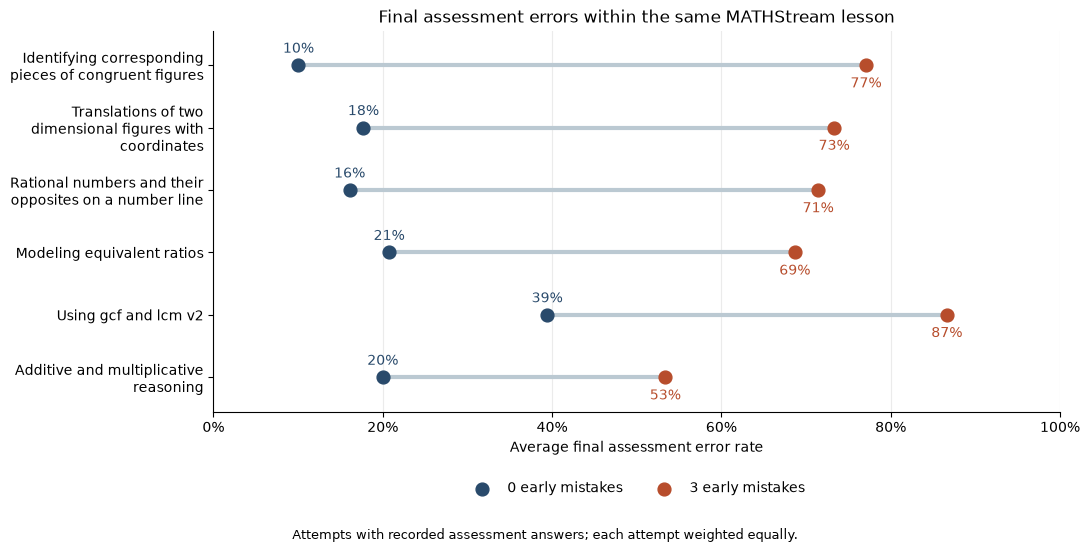

Higher assessment error rate after 3 vs. 0 mistakes in 6 of 6 displayed streams.


In [7]:
if top.empty:
    print("No streams meet the minimum count in both endpoint groups.")
else:
    top.to_csv(results / "selected_stream_comparison.csv")
    display(top[["n_zero", "n_three", "rate_zero", "rate_three", "gap_pp"]]
            .assign(rate_zero=lambda d: 100 * d["rate_zero"],
                    rate_three=lambda d: 100 * d["rate_three"])
            .round(1))

    fig, ax = plt.subplots(figsize=(11, 5.5))
    y = range(len(top))
    ax.hlines(y, top["rate_zero"], top["rate_three"], color="#BBC9D2", linewidth=3)
    ax.scatter(top["rate_zero"], y, color="#294A6B", s=85, label="0 early mistakes", zorder=3)
    ax.scatter(top["rate_three"], y, color="#B74D2C", s=85, label="3 early mistakes", zorder=3)

    for i, row in enumerate(top.itertuples()):
        ax.annotate(f"{row.rate_zero:.0%}", (row.rate_zero, i),
                    xytext=(0, 9), textcoords="offset points", ha="center", color="#294A6B")
        ax.annotate(f"{row.rate_three:.0%}", (row.rate_three, i),
                    xytext=(0, -16), textcoords="offset points", ha="center", color="#B74D2C")

    ax.set_yticks(
        list(y),
        [fill(str(name).replace("-", " ").capitalize(), 30) for name in top.index]
    )
    ax.set(xlim=(0, 1), ylim=(-0.55, len(top) - 0.45),
           xlabel="Average final assessment error rate",
           title="Final assessment errors within the same MATHStream lesson")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="x", alpha=.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.15), ncol=2, frameon=False)
    fig.text(.5, .01, "Attempts with recorded assessment answers; each attempt weighted equally.",
             ha="center", fontsize=9)
    fig.tight_layout(rect=(0, .04, 1, 1))

    fig.savefig(results / "assessment_errors_within_stream.png", dpi=220, bbox_inches="tight")
    plt.show()

    print(f"Higher assessment error rate after 3 vs. 0 mistakes in "
          f"{top['gap_pp'].gt(0).sum()} of {len(top)} displayed streams.")

,0 mistakes,1 mistakes,2 mistakes,3 mistakes
lessonstreamname,,,,
identifying-corresponding-pieces-of-congruent-figures,10.0% (n=446),16.5% (n=203),27.9% (n=78),77.1% (n=48)
translations-of-two-dimensional-figures-with-coordinates,17.7% (n=317),28.4% (n=250),42.5% (n=160),73.3% (n=89)
rational-numbers-and-their-opposites-on-a-number-line,16.1% (n=404),30.5% (n=300),48.2% (n=55),71.4% (n=35)
modeling-equivalent-ratios,20.8% (n=53),26.6% (n=124),37.1% (n=163),68.7% (n=399)
using-gcf-and-lcm-v2,39.4% (n=222),50.0% (n=216),71.5% (n=219),86.6% (n=258)
additive-and-multiplicative-reasoning,20.0% (n=60),27.1% (n=260),37.2% (n=513),53.4% (n=429)


Lessons with at least 30 attempts in all four groups: 6 of 6
Of those, lessons where the rate rose at every step: 6 of 6


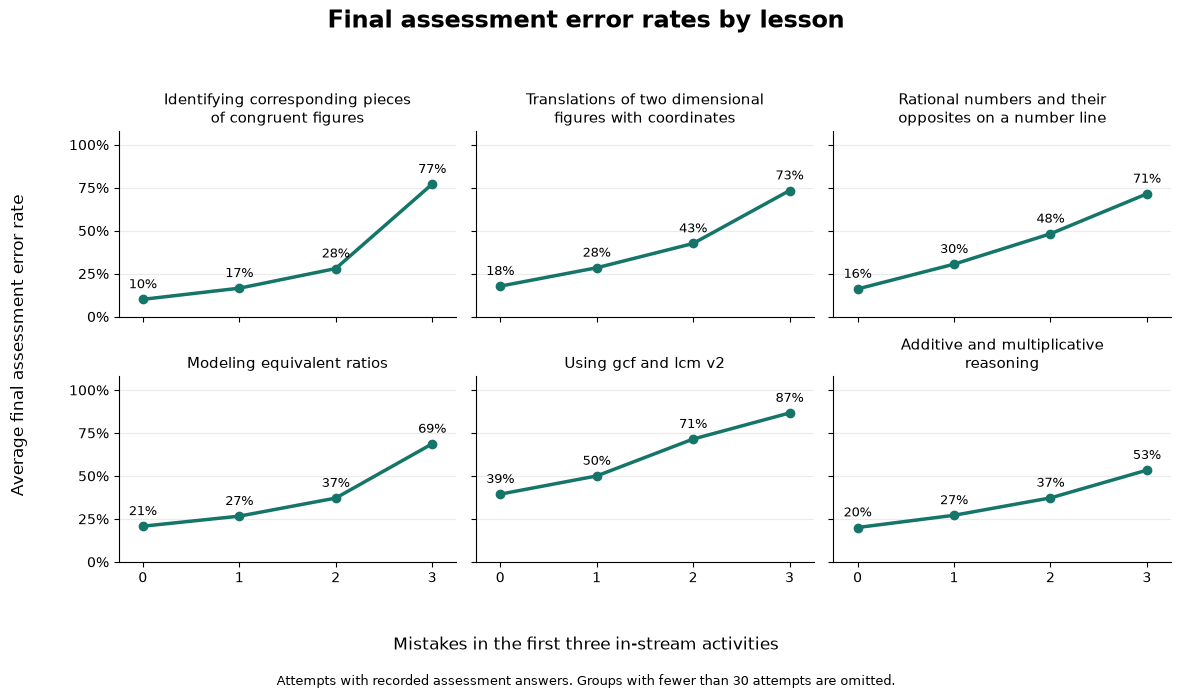

In [8]:
if top.empty:
    print("No streams meet the minimum count in both endpoint groups.")
else:
    groups = [0, 1, 2, 3]
    lessons = top.index[::-1]
    min_n = min_stream_attempts

    summary = (
        assessment.loc[
            assessment["lessonstreamname"].isin(lessons)
            & assessment["early_errors"].isin(groups)
        ]
        .groupby(["lessonstreamname", "early_errors"])["error_rate"]
        .agg(rate="mean", n="count")
    )

    rates = summary["rate"].unstack().reindex(index=lessons, columns=groups)
    counts = (
        summary["n"].unstack()
        .reindex(index=lessons, columns=groups)
        .fillna(0).astype(int)
    )

    summary.to_csv(results / "selected_streams_all_error_groups.csv")

    # Table: percentage and number of attempts behind each group
    table = pd.DataFrame(index=lessons)
    for g in groups:
        table[f"{g} mistakes"] = [
            f"{r:.1%} (n={n:,})" if pd.notna(r) else "—"
            for r, n in zip(rates[g], counts[g])
        ]
    display(table)

    # Check the step-by-step pattern only where all four groups have enough data
    supported = counts.ge(min_n).all(axis=1)
    rises_each_step = rates.diff(axis=1)[[1, 2, 3]].gt(0).all(axis=1)

    print(f"Lessons with at least {min_n} attempts in all four groups: "
          f"{supported.sum()} of {len(lessons)}")
    print(f"Of those, lessons where the rate rose at every step: "
          f"{(supported & rises_each_step).sum()} of {supported.sum()}")
    rows = (len(lessons) + 2) // 3
    fig, axes = plt.subplots(rows, 3, figsize=(12, 3.5 * rows), sharex=True, sharey=True)

    for ax, lesson in zip(axes.flat, lessons):
        shown = rates.loc[lesson].where(counts.loc[lesson].ge(min_n))
        ax.plot(groups, shown, marker="o", linewidth=2.5, color="#147568")

        for g, rate in shown.dropna().items():
            ax.annotate(f"{rate:.0%}", (g, rate), xytext=(0, 8),
                        textcoords="offset points", ha="center", fontsize=9)

        ax.set_title(fill(str(lesson).replace("-", " ").capitalize(), 32), fontsize=11)
        ax.set(xticks=groups, xlim=(-0.25, 3.25), ylim=(0, 1.08))
        ax.set_yticks([0, .25, .50, .75, 1])
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis="y", alpha=.25)
        ax.spines[["top", "right"]].set_visible(False)

    for ax in list(axes.flat)[len(lessons):]:
        ax.set_visible(False)

    fig.suptitle("Final assessment error rates by lesson", fontsize=17, fontweight="bold")
    fig.supxlabel("Mistakes in the first three in-stream activities", y=.06)
    fig.supylabel("Average final assessment error rate")
    fig.text(.5, .015,
             f"Attempts with recorded assessment answers. Groups with fewer than {min_n} attempts are omitted.",
             ha="center", fontsize=9)
    fig.tight_layout(rect=(.03, .09, 1, .94))

    fig.savefig(results / "assessment_errors_all_four_groups.png",
                dpi=220, bbox_inches="tight")
    plt.show()

## 6. Check class coverage and audit status, passing and score

The class diagnostic counts streams with enough eligible assessment attempts in both endpoint groups within the same class. For the largest selected stream, it also compares assessment availability and error rates in supported classes. Output masks class IDs. The status and score tables show how recorded completion and pass status relate in this extract, including the score band around 60%. These are diagnostics and do not filter the assessment cohort.

In [9]:
class_counts = (
    assessment.loc[assessment["early_errors"].isin([0, 3])]
    .groupby(["lessonstreamname", "anon_classid", "early_errors"])
    .size().unstack(fill_value=0)
    .reindex(columns=[0, 3], fill_value=0)
    .rename(columns={0: "n_zero", 3: "n_three"})
)
supported = class_counts.loc[class_counts.ge(min_class_attempts).all(axis=1)]
classes_per_stream = supported.groupby(level="lessonstreamname").size().sort_values(ascending=False)
classes_per_stream = classes_per_stream.rename("classes_with_both_groups")
display(classes_per_stream.to_frame().head(10))
classes_per_stream.to_csv(results / "class_coverage_by_stream.csv")

if not top.empty:
    stream = top["total"].idxmax()
    class_base = cohort.merge(meta, on=keys, how="left", validate="one_to_one")
    class_base = class_base.loc[
        class_base["lessonstreamname"].eq(stream)
        & class_base["anon_classid"].notna()
        & class_base["early_errors"].isin([0, 3])
    ].merge(eligible[keys + ["error_rate"]], on=keys, how="left", validate="one_to_one")
    by_class = class_base.groupby(["anon_classid", "early_errors"]).agg(
        early_attempts=("attemptid", "size"),
        assessed_attempts=("eligible_assessment", "sum"),
        eligible_assessment_pct=("eligible_assessment", lambda s: 100 * s.mean()),
        assessment_error_pct=("error_rate", lambda s: 100 * s.mean()),
    ).reset_index()
    keep = supported.loc[supported.index.get_level_values("lessonstreamname") == stream]
    shown = by_class.loc[by_class["anon_classid"].isin(keep.index.get_level_values("anon_classid"))].copy()
    shown["class"] = pd.factorize(shown.pop("anon_classid"))[0] + 1
    print(f"{stream}: {len(keep)} classes with at least {min_class_attempts} assessment attempts per endpoint group.")
    display(shown.round(2))

,classes_with_both_groups
lessonstreamname,
using-transformations-to-graph-quadratic-functions,2
composing-and-decomposing-composite-figures,1
vertical-dilations-and-vertical-translations-of-functions,1


identifying-corresponding-pieces-of-congruent-figures: 0 classes with at least 10 assessment attempts per endpoint group.


,early_errors,early_attempts,assessed_attempts,eligible_assessment_pct,assessment_error_pct,class


In [10]:
# Separate audit: recorded status vs recorded pass flag; preserve missing values.
status = a["status"].astype("string").str.upper().fillna("Missing")
passed = pd.to_numeric(a["passedattempt"], errors="coerce")
flag = passed.map({0: "Did not pass", 1: "Passed"}).fillna("Missing / other")
status_pass = pd.crosstab(status.rename("Status"), flag.rename("Pass flag"), margins=True)
display(status_pass)
status_pass.to_csv(results / "status_by_pass_flag.csv")
score = pd.to_numeric(a["score"], errors="coerce")
maximum = pd.to_numeric(a["scoremaximum"], errors="coerce")
valid = maximum.gt(0) & score.between(0, maximum)
delta = 5 * score - 3 * maximum
band = np.select([(valid & condition).fillna(False).to_numpy(dtype=bool) for condition in [delta.lt(0), delta.eq(0), delta.gt(0)]],
                 ["Below 60%", "Exactly 60%", "Above 60%"], default="Missing / invalid")
done = status.eq("COMPLETED")
score_pass = pd.crosstab(pd.Series(band, index=a.index, name="Score band")[done],
                         flag[done].rename("Pass flag"), margins=True)
display(score_pass)
score_pass.to_csv(results / "completed_score_band_by_pass_flag.csv")

Pass flag,Did not pass,Missing / other,Passed,All
Status,,,,
COMPLETED,86102,0,46086,132188
IN_PROGRESS,0,64399,0,64399
All,86102,64399,46086,196587


Pass flag,Did not pass,Passed,All
Score band,,,
Above 60%,0,46086,46086
Below 60%,77411,0,77411
Exactly 60%,8527,0,8527
Missing / invalid,164,0,164
All,86102,46086,132188


## Interpretation

Report the four group means with their attempt counts, the percentage-point difference between three and zero mistakes, and the assessment coverage rates. The outcome describes scored answers in attempts with an observed, correctly ordered assessment. Attempts without a usable assessment may differ from the analyzed attempts. Within-stream comparisons address differences between the selected lessons while leaving student and classroom differences open. This notebook estimates descriptive associations.